In [ ]:
import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
path = kagglehub.competition_download('cats-and-dogs-plus-plus')

print("Path to competition files:", path)

100%|██████████| 1.66G/1.66G [00:22<00:00, 81.0MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/cats-and-dogs-plus-plus


In [ ]:
import os
import pandas as pd

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level <= 1:
        print("  " * level + os.path.basename(root) + "/", f"({len(files)} файлів)")
        for f in files[:5]:
            print("  " * (level + 1) + f)

csvs = [f for f in os.listdir(path) if f.endswith(".csv")]
for c in csvs:
    print(f"\n=== {c} ===")
    df = pd.read_csv(os.path.join(path, c))
    print(df.shape)
    print(df.head())

cats-and-dogs-plus-plus/ (3 файлів)
  sample_submission.csv
  test.csv
  train.csv
  train/ (12260 файлів)
    8e75eb7fd6421c8a83c2d3a6bed6f4ce2282c16c.jpg
    d41922c1797c6a84d799b5a581c80b20ea9e6476.jpg
    c8dfaa3571f77ed508ff47107ee4bf6cfab9df5d.jpg
    f4624bfc725aa1551823086d2a53d139da8be97d.jpg
    cc86ce2c11eb81056a6363600241b6a1e7a6342c.jpg
  test/ (18390 файлів)
    428ff1cadc4624596c96592d1d49dcd9f4c10a54.jpg
    fec8374813560553797eec7fcf064e6966afa655.jpg
    d26228f7c52e62586d90abf6b0c0266c9033ed5d.jpg
    02feeabb5ec0837d4ebf0e2746ac4ad498ef1652.jpg
    5882fba2bccf75aaaa6d4c9623c2adf2e312c7ea.jpg

=== sample_submission.csv ===
(18390, 6)
                                   image_id  Cat  Dog  Moris  Motya  Biatrix
0  7e9de2837ab0f90176c0e6c2e30c2c136f1f00d9    1    1      1      1        1
1  11e8173dd91e7a00f8bdbc64067d6f167c9bbed2    1    1      1      1        1
2  415c62c8d85c0a13300ba25f4a5e6582eb468c31    1    1      1      1        1
3  4fbdedc390d83a9b264dc8e0ea8

In [ ]:
train_df = pd.read_csv(os.path.join(path, "train.csv"))
test_df = pd.read_csv(os.path.join(path, "test.csv"))

In [ ]:
import os
import pandas as pd
from PIL import Image

def read_exif(img_path):
    try:
        exif = Image.open(img_path).getexif()

        sub = exif.get_ifd(0x8769)

        date = sub.get(36867) or exif.get(306)

        model = exif.get(272)

        return date, model, len(exif)

    except Exception:
        return None, None, 0

def exif_table(df, folder, n=500):
    sample = df.sample(min(n, len(df)), random_state=0)
    paths = sample["image_id"].apply(lambda x: os.path.join(path, folder, f"{x}.jpg"))
    res = pd.DataFrame(paths.apply(read_exif).tolist(),
                       columns=["date", "model", "n_tags"], index=sample.index)
    return res

train_exif = exif_table(train_df, "train")
test_exif = exif_table(test_df, "test")

for name, res in [("train", train_exif), ("test", test_exif)]:
    print(f"=== {name} (вибірка {len(res)}) ===")
    print(f"  мають хоч якийсь EXIF: {(res['n_tags'] > 0).mean():.1%}")
    print(f"  мають дату:            {res['date'].notna().mean():.1%}")
    print(f"  мають модель камери:   {res['model'].notna().mean():.1%}")

    if res["model"].notna().any():
        print("  топ моделей:", res["model"].value_counts().head(5).to_dict())

=== train (вибірка 500) ===
  мають хоч якийсь EXIF: 0.0%
  мають дату:            0.0%
  мають модель камери:   0.0%
=== test (вибірка 500) ===
  мають хоч якийсь EXIF: 0.0%
  мають дату:            0.0%
  мають модель камери:   0.0%


We check EXIF and like result understood that we dont have any watermark like date, camera model and something like that. If we know it we could say that its not depend from the time.

In [ ]:
!pip install -q faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 30.5 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import timm
import faiss
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=0).eval().to(DEVICE)
cfg = timm.data.resolve_data_config({}, model=model)
transform = timm.data.create_transform(**cfg)


class ImageDataset(Dataset):
    def __init__(self, ids, folder):
        self.paths = [os.path.join(path, folder, f"{i}.jpg") for i in ids]

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        return transform(Image.open(self.paths[idx]).convert("RGB"))


@torch.no_grad()
def get_embeddings(ids, folder, batch_size=128):
    loader = DataLoader(ImageDataset(ids, folder), batch_size=batch_size, num_workers=2)
    out = []
    for x in tqdm(loader, desc=folder):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            out.append(model(x.to(DEVICE)).float().cpu())
    emb = torch.cat(out).numpy().astype("float32")
    faiss.normalize_L2(emb)
    return emb


train_emb = get_embeddings(train_df["image_id"], "train")
test_emb = get_embeddings(test_df["image_id"], "test")
print(train_emb.shape, test_emb.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

train:   0%|          | 0/96 [00:00<?, ?it/s]

test:   0%|          | 0/144 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
!pip install imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 5.7 MB/s eta 0:00:00


In [ ]:
import os, hashlib
import numpy as np
import pandas as pd
import imagehash
from PIL import Image
from tqdm.auto import tqdm

def compute_hashes(df, folder):
    md5s, phashes = [], []
    for img_id in tqdm(df["image_id"], desc=folder):
        p = os.path.join(path, folder, f"{img_id}.jpg")
        with open(p, "rb") as f:
            md5s.append(hashlib.md5(f.read()).hexdigest())
        phashes.append(imagehash.phash(Image.open(p)).hash.flatten())
    return md5s, np.array(phashes, dtype=np.uint8)

train_df["md5"], train_bits = compute_hashes(train_df, "train")
test_df["md5"], test_bits = compute_hashes(test_df, "test")
print(train_bits.shape, test_bits.shape)    # (12260, 64) (18390, 64)

train:   0%|          | 0/12260 [00:00<?, ?it/s]

test:   0%|          | 0/18390 [00:00<?, ?it/s]

(12260, 64) (18390, 64)


In [ ]:
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

dup = train_df[train_df.duplicated("md5", keep=False)]
print("точних дублікатів у train:", len(dup), "фото,", dup["md5"].nunique(), "груп")

conflicts = dup.groupby("md5")[LABELS].nunique().max(axis=1)
print("груп з різними мітками:", (conflicts > 1).sum())

common = set(train_df["md5"]) & set(test_df["md5"])
print("точних дублікатів train ↔ test:", len(common))

точних дублікатів у train: 10 фото, 5 груп
груп з різними мітками: 0
точних дублікатів train ↔ test: 14


In [ ]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def hamming_pairs(bits_a, bits_b, max_dist, same=False, chunk=2048):
    a_all = torch.from_numpy(bits_a).float().to(DEVICE)
    b = torch.from_numpy(bits_b).float().to(DEVICE)
    rows = []
    for start in range(0, len(a_all), chunk):
        a = a_all[start:start + chunk]

        d = a @ (1 - b).T + (1 - a) @ b.T
        i, j = torch.nonzero(d <= max_dist, as_tuple=True)
        i = i + start
        if same:
            keep = i < j
            i, j = i[keep], j[keep]
        rows.append(torch.stack([i, j, d[i - start, j].long()], 1).cpu())
    return pd.DataFrame(torch.cat(rows).numpy(), columns=["a", "b", "dist"])

pairs = hamming_pairs(train_bits, train_bits, max_dist=12, same=True)
print(pairs["dist"].value_counts().sort_index())

dist
0     124
2      38
6       1
8       7
10     41
12    384
Name: count, dtype: int64


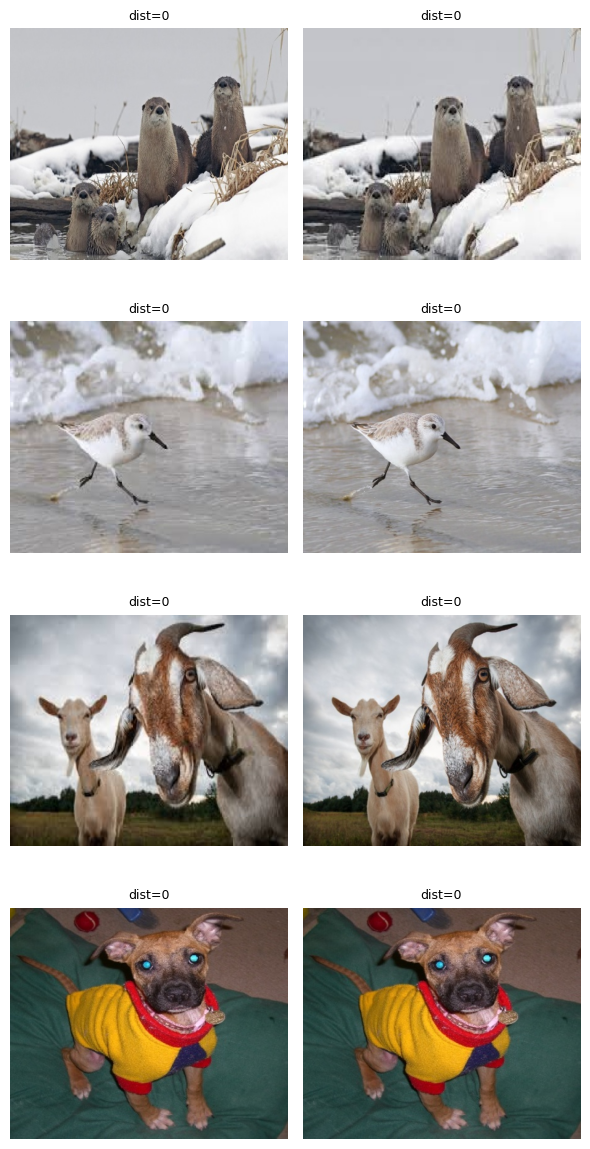

немає пар для [3, 4, 5]


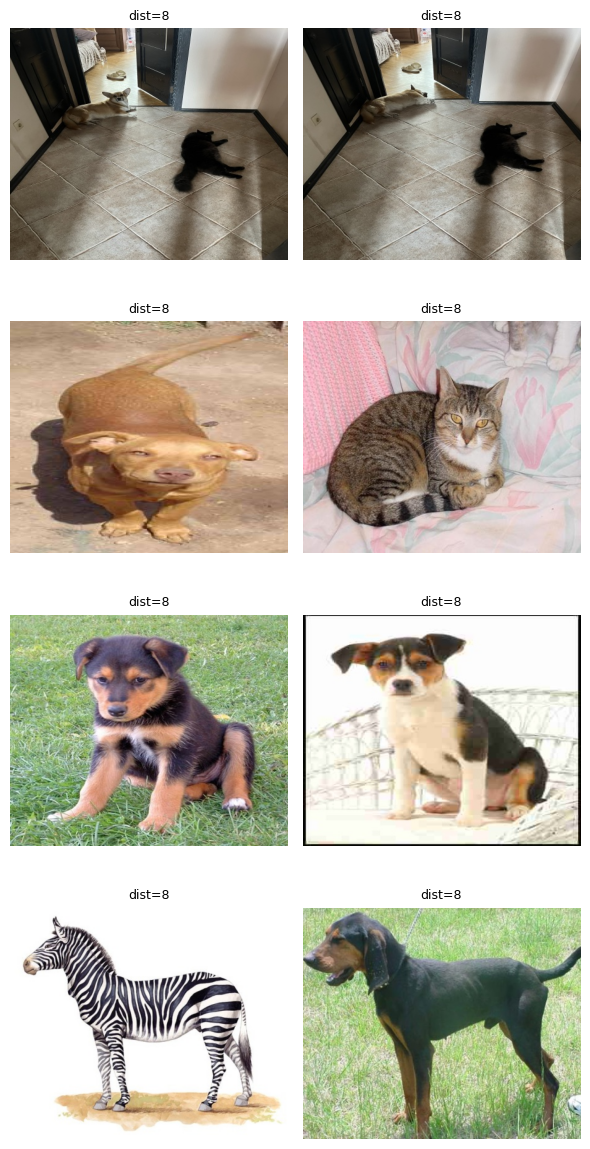

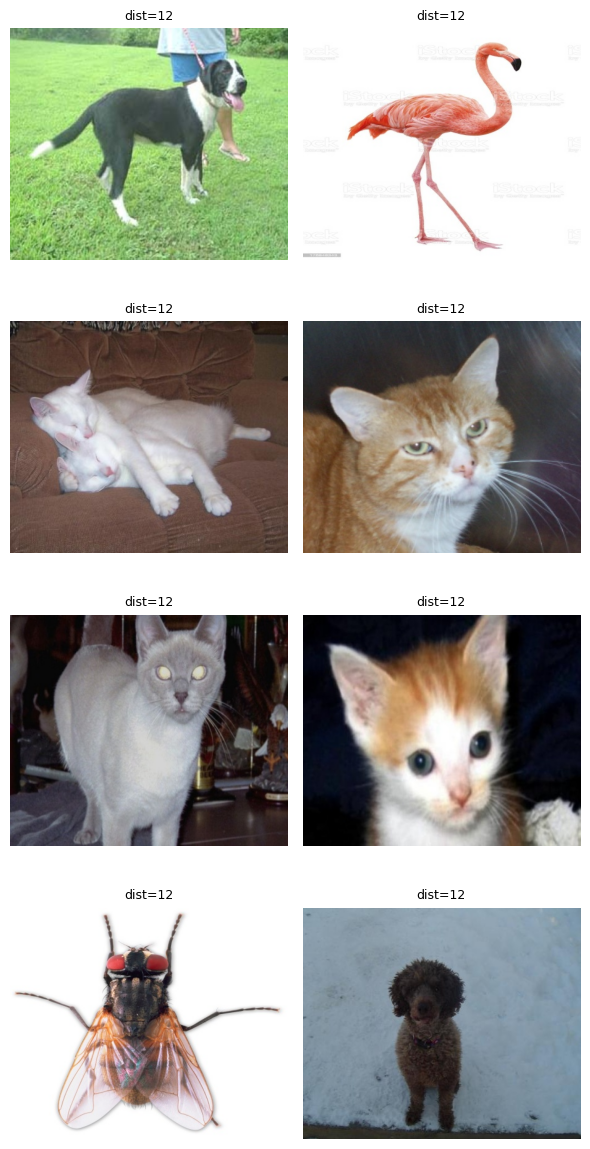

In [ ]:
import matplotlib.pyplot as plt

def show_pairs(dist_values, n_show=4):
    sub = pairs[pairs["dist"].isin(dist_values)]
    sub = sub.sample(min(n_show, len(sub)), random_state=0)
    if len(sub) == 0:
        print("немає пар для", dist_values); return
    fig, axes = plt.subplots(len(sub), 2, figsize=(6, 3 * len(sub)))
    for row, (_, p) in zip(np.atleast_2d(axes), sub.iterrows()):
        for ax, idx in zip(row, [p["a"], p["b"]]):
            img_id = train_df["image_id"].iloc[int(idx)]
            ax.imshow(Image.open(os.path.join(path, "train", f"{img_id}.jpg")))
            ax.set_title(f"dist={p['dist']}", fontsize=9)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_pairs([0, 1, 2])
show_pairs([3, 4, 5])
show_pairs([6, 7, 8])
show_pairs([9, 10, 11, 12])

In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

n = len(train_df)

def make_groups(max_dist):
    p = pairs[pairs["dist"] <= max_dist]
    graph = coo_matrix((np.ones(len(p)), (p["a"], p["b"])), shape=(n, n))
    _, groups = connected_components(graph, directed=False)
    return groups

for t in [2, 4, 6, 8, 10]:
    sizes = pd.Series(make_groups(t)).value_counts()
    multi = sizes[sizes > 1]
    print(f"dist≤{t}: груп з >1 фото: {len(multi)}, фото в них: {multi.sum()} "
          f"({multi.sum() / n:.1%}), найбільша група: {sizes.max()}")

In [ ]:
perc = 10 / len(train_df)
print(f"{perc:.2%}")

0.08%


We found five exact match pictures in train, but it just 0.08% from the whole train, if be short - doesnt matter. group leakage is not a major concern for validation

We choose a couple of split method which on our opinion will be match with our classification task

1. MultilabelStratifiedKFold
2. StratifiedGroupKFold

Why? Because.


Just joke, sorry

We decide that we should use some split which will be with stratification because we have classes with no a lot of example and because of it we even can have situation that no one example of some class will be in some fold and it will be big problem.

How we will decide between this two methods, in easy way we have clear favorit player here - its first method, and if we will not find advantage for second method he will lose.

Which advantage can have second method, only one - the second method will not give opportunity to situation when photo from one series will be in train and val, it prevent data leakege because without it we will have situation when we validate our model on the same pictures on which we train.

Now we understand that series which we describe above we can count on one hand (if you have 162 finger): near-duplicate series affect only about 2–3% of the training data, so they will not affect the results much.


Because of it we will use first method, 5 folds with a fixed random_state = 42, so all experiments use the same splits